# Parte 2 · Ajuste a CDNOW, interpretación y bootstrap

**Autor:** Jorge Armando Ferguson Yaeggy · Grupo 1

**Declaración de uso de IA:** el notebook, la extensión de diagnóstico del ajuste y las pruebas se elaboraron con apoyo de Codex (OpenAI). Se reutilizan la preparación de datos de Sofía (`cargar_cdnow`, `resumen_clientes`) y el ajuste manual de Herman (`ajustar_bgnbd`).

Ejecutar desde `notebooks/` mediante **Restart & Run All**. Reconstruye los datos desde el archivo original y ejecuta las **200** réplicas del bootstrap. `lifetimes` solo se usa para verificar; el ajuste publicado es el de `src/bgnbd.py`.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata as metadata
import json
import platform
import re
import sys
import warnings

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
from scipy.stats import gamma, beta
from lifetimes import BetaGeoFitter
from IPython.display import display, Markdown

RAIZ = Path.cwd().resolve().parent
assert (RAIZ / 'src/datos.py').is_file(), 'Ejecutar desde notebooks/'
sys.path.insert(0, str(RAIZ / 'src'))
from datos import cargar_cdnow, resumen_clientes
from bgnbd import ajustar_bgnbd, loglik_bgnbd, PARAMS_ARTICULO, NOMBRES
from bootstrap_cdnow import bootstrap_clientes

FIN_CALIB, FIN_HOLDOUT = '1997-09-30', '1998-06-30'
B, SEMILLA, SEMILLA_REINTENTOS = 200, 14045, 271828
SEMANAS_ANIO = 52
RESULTADOS, FIGS = RAIZ / 'resultados', RAIZ / 'figs'
RESULTADOS.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)
pd.set_option('display.precision', 16)

def sha256(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()

def guardar_json(nombre, contenido):
    (RESULTADOS / nombre).write_text(
        json.dumps(contenido, ensure_ascii=False, indent=2, allow_nan=False) + '\n', encoding='utf-8')

versiones = {p: metadata.version(p) for p in
             ['numpy', 'pandas', 'scipy', 'matplotlib', 'lifetimes', 'autograd',
              'nbformat', 'nbclient', 'ipykernel', 'openpyxl']}
versiones['python'] = platform.python_version()
display(pd.Series(versiones, name='Versión').to_frame())

,Versión
numpy,2.5.4
pandas,3.1.0
scipy,1.18.1
matplotlib,3.11.2
lifetimes,0.11.3
autograd,1.9.1
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0
openpyxl,3.1.5


## 2.1 · Historias y ajuste manual

Se agrupan primero las compras del mismo cliente y día. La adquisición es la
primera compra; `x` excluye esa compra, `tx` mide hasta la última repetida y `T`
hasta el corte, siempre en semanas. Se conservan los clientes con `x=0`.
Calibración hasta el 30/09/1997 inclusive; holdout del 01/10/1997 al 30/06/1998.

In [2]:
ruta_datos = RAIZ / 'data/CDNOW_sample.txt'
crudo = pd.read_csv(ruta_datos, sep=r'\s+', header=None)
trans = cargar_cdnow(ruta_datos)
res = resumen_clientes(trans, FIN_CALIB, FIN_HOLDOUT)
x, tx, T = (res[k].to_numpy(dtype=float) for k in ['x', 'tx', 'T'])
assert not trans.duplicated(['cliente', 'fecha']).any()
assert len(trans) == len(crudo.groupby([1, 2]))
assert np.isfinite(np.column_stack([x, tx, T])).all()
assert np.all((x >= 0) & (x == np.floor(x)))
assert np.all((tx >= 0) & (tx <= T))
assert np.all(tx[x == 0] == 0)
assert res['cliente'].is_unique
conteos = {
    'registros_originales': len(crudo), 'transacciones_cliente_dia': len(trans),
    'clientes_calibracion': len(res), 'clientes_x_cero': int((x == 0).sum()),
    'repetidas_calibracion': int(x.sum()), 'compras_holdout': int(res.x_star.sum()),
}
esperados = {'clientes_calibracion': 2357, 'clientes_x_cero': 1411,
             'repetidas_calibracion': 2457, 'compras_holdout': 1882}
assert all(conteos[k] == v for k, v in esperados.items()), conteos
display(pd.Series(conteos, name='Conteo verificado').to_frame())
print(f'T: {T.min():.12g}–{T.max():.12g} semanas; unidades: días / 7')

,Conteo verificado
registros_originales,6919
transacciones_cliente_dia,6696
clientes_calibracion,2357
clientes_x_cero,1411
repetidas_calibracion,2457
compras_holdout,1882


T: 27–38.8571428571 semanas; unidades: días / 7


### Política de aceptación del optimizador

Se conserva el ajuste de Herman: minimizar `−LL/n` con Nelder–Mead y L-BFGS-B,
log-parámetros y cotas `[-10,10]`. Los tres arranques predeterminados son unos,
artículo y un vector de `default_rng(0)`.

La extensión optativa `devolver_diagnostico=True` devuelve `(estimados, diagnostico)`;
sin ella se mantiene el diccionario numérico habitual. Solo son utilizables los
intentos con `success=True`, objetivo finito y parámetros positivos finitos dentro
de las cotas. Estar en una cota se informa por separado de converger.

Una mejora de un intento rechazado mayor que `1e-7` en `−LL/n` exige un reintento
con ambos métodos desde ese punto. Si persiste, se rechaza el ajuste y se conservan
los intentos en `ErrorAjuste.diagnostico`. El acuerdo se evalúa en LL, sin exigir
parámetros idénticos en regiones planas. No se ocultan intentos fallidos.

In [3]:
estimado, diagnostico = ajustar_bgnbd(x, tx, T, devolver_diagnostico=True)
params = {k: estimado[k] for k in NOMBRES}
log_completo = np.log([params[k] for k in NOMBRES])
assert diagnostico['aceptado'] and not diagnostico['en_cota']
ll_manual = loglik_bgnbd(log_completo, x, tx, T)
assert abs(ll_manual - estimado['ll']) < 1e-8
display(pd.DataFrame(diagnostico['intentos'])[
    ['id', 'metodo', 'indice_inicio', 'success', 'status', 'objetivo',
     'nit', 'nfev', 'en_cota', 'utilizable']])
print('Intento seleccionado:', diagnostico['seleccionado'])
print('Rango LL entre soluciones exitosas:', diagnostico['rango_ll_exitosos'])
print('Acuerdo en LL:', diagnostico['acuerdo_ll_exitosos'])
print('Parámetros completos:', json.dumps(params, ensure_ascii=False))
print('LL sumada:', repr(ll_manual))

,id,metodo,indice_inicio,success,status,objetivo,nit,nfev,en_cota,utilizable
0,0,Nelder-Mead,0,True,0,4.0655193918854184,413,714,[],True
1,1,L-BFGS-B,0,True,0,4.0655193918855490,17,100,[],True
2,2,Nelder-Mead,1,True,0,4.0655193918854193,106,224,[],True
3,3,L-BFGS-B,1,True,0,4.0655193918948038,7,40,[],True
4,4,Nelder-Mead,2,True,0,4.0655193918854176,357,636,[],True
5,5,L-BFGS-B,2,True,0,4.0655193918869621,19,125,[],True


Intento seleccionado: 4
Rango LL entre soluciones exitosas: 2.2123437304344407e-08
Acuerdo en LL: True
Parámetros completos: {"r": 0.24259452951758145, "alpha": 4.413602204637224, "a": 0.7929221046424372, "b": 2.42590701103797}
LL sumada: -9582.429206673929


In [4]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', UserWarning)
    bgf = BetaGeoFitter(penalizer_coef=0.0).fit(x, tx, T)
params_ref = {k: float(bgf.params_[k]) for k in NOMBRES}
ll_ref = loglik_bgnbd(np.log([params_ref[k] for k in NOMBRES]), x, tx, T)
ll_articulo = loglik_bgnbd(np.log([PARAMS_ARTICULO[k] for k in NOMBRES]), x, tx, T)
comparacion = pd.DataFrame({
    'Manual': [params[k] for k in NOMBRES] + [ll_manual],
    'lifetimes (sin penalización)': [params_ref[k] for k in NOMBRES] + [ll_ref],
    'Artículo (redondeado)': [PARAMS_ARTICULO[k] for k in NOMBRES] + [-9582.4],
}, index=[*NOMBRES, 'LL sumada'])
comparacion['Diferencia manual − lifetimes'] = comparacion.iloc[:, 0] - comparacion.iloc[:, 1]
display(comparacion)
TOL_PARAM_RTOL, TOL_PARAM_ATOL, TOL_LL = 2e-4, 2e-5, 1e-5
np.testing.assert_allclose([params[k] for k in NOMBRES], [params_ref[k] for k in NOMBRES],
                           rtol=TOL_PARAM_RTOL, atol=TOL_PARAM_ATOL)
assert abs(ll_manual - ll_ref) < TOL_LL
assert abs(ll_manual - (-9582.4)) < .05  # referencia redondeada a una decimal
print('Máxima diferencia absoluta de parámetros:',
      max(abs(params[k] - params_ref[k]) for k in NOMBRES))
print('Diferencia absoluta de LL:', abs(ll_manual - ll_ref))
print('LL propia en parámetros redondeados del artículo:', ll_articulo)

,Manual,lifetimes (sin penalización),Artículo (redondeado),Diferencia manual − lifetimes
r,0.2425945295175815,0.2425945434210671,0.2430000000000000,-0.0000000139034857
alpha,4.4136022046372236,4.4136027160773788,4.4139999999999997,-0.0000005114401551
a,0.7929221046424372,0.7929218333480146,0.7930000000000000,0.0000002712944226
b,2.4259070110379701,2.4259057287223023,2.4260000000000002,0.0000012823156679
LL sumada,-9582.4292066739290021,-9582.4292066739362781,-9582.3999999999996362,0.0000000000072760


Máxima diferencia absoluta de parámetros: 1.2823156678720693e-06
Diferencia absoluta de LL: 7.275957614183426e-12
LL propia en parámetros redondeados del artículo: -9582.430478013672


La tabla usa exactamente las mismas historias y evalúa ambas soluciones con la
LL **sumada** del repositorio. `lifetimes` 0.11.3 escala internamente el tiempo y
optimiza una LL negativa media; por ello no se compara directamente su objetivo
interno con nuestra LL. La tolerancia de parámetros (`rtol=2e-4`, `atol=2e-5`) admite
pequeñas diferencias numéricas en una superficie plana; el criterio adicional de
LL (`1e-5` absoluto) exige equivalencia del ajuste. Las diferencias reales se muestran
arriba; los valores del artículo son referencias redondeadas, no estimados insertados.

> **Pregunta 2.1.** Estimen $(r, \alpha, a, b)$ y reporten la log-verosimilitud en el óptimo. Compárenlos con los del artículo.

Con los datos de calibración obtenemos $r = 0.2426$, $\alpha = 4.4136$, $a = 0.7929$ y $b = 2.4259$, con log-verosimilitud **−9582.43**. Redondeados a tres decimales son exactamente los del artículo ($r = 0.243$, $\alpha = 4.414$, $a = 0.793$, $b = 2.426$; LL ≈ −9582.4), así que tanto la construcción de $(x, t_x, T)$ como la verosimilitud están bien. `lifetimes.BetaGeoFitter` sin penalización llega a los mismos parámetros (diferencias del orden de $10^{-6}$). Estos estimados se guardan en `resultados/params_cdnow.json` y los usan las Partes 3, 4 y 6.

In [5]:
guardar_json('params_cdnow.json', params)
proveniencia = {
    'productor': 'notebooks/02_ajuste_cdnow.ipynb', 'seccion': '2.1',
    'naturaleza': 'ajuste manual validado; reemplaza semilla del artículo',
    'parametros': params, 'll_sumada': ll_manual,
    'datos': {'ruta': 'data/CDNOW_sample.txt', 'sha256': sha256(ruta_datos)},
    'fin_calibracion': FIN_CALIB, 'inicio_holdout': '1997-10-01',
    'fin_holdout': FIN_HOLDOUT, 'unidad_tiempo': 'semanas (días / 7)',
    'conteos': conteos, 'T_min': float(T.min()), 'T_max': float(T.max()),
    'orden_clientes': 'orden de filas de resumen_clientes; cliente ascendente',
    'versiones': versiones, 'diagnostico': diagnostico,
    'verificacion_lifetimes': {'penalizer_coef': 0.0, 'parametros': params_ref,
        'll_sumada_propia': ll_ref, 'diferencias_manual_menos_lifetimes':
        {k: params[k] - params_ref[k] for k in NOMBRES},
        'diferencia_ll': ll_manual - ll_ref,
        'tolerancias': {'rtol_parametros': TOL_PARAM_RTOL,
                        'atol_parametros': TOL_PARAM_ATOL, 'atol_ll': TOL_LL}},
    'codigo_sha256': {f'src/{f}': sha256(RAIZ / 'src' / f)
                      for f in ['bgnbd.py', 'datos.py', 'bootstrap_cdnow.py']},
}
guardar_json('ajuste_cdnow_proveniencia.json', proveniencia)
publicado = json.loads((RESULTADOS / 'params_cdnow.json').read_text())
assert set(publicado) == set(NOMBRES)
assert all(type(v) is float and np.isfinite(v) and v > 0 for v in publicado.values())
assert publicado == proveniencia['parametros'] == params
print('Publicado params_cdnow.json con exactamente cuatro claves; diagnóstico separado.')

Publicado params_cdnow.json con exactamente cuatro claves; diagnóstico separado.


## 2.2 · Interpretación de la heterogeneidad

El modelo usa `λ ~ Gamma(r, tasa α)` y `p ~ Beta(a,b)`. `r/α` es la intensidad media
semanal de compra mientras se está activo, y `a/(a+b)` la probabilidad media latente
de abandonar después de una compra **repetida**. La compra de adquisición no activa
la muerte en BG/NBD. La intensidad anualizada usa **52 semanas por año**; las compras
realizadas de una cohorte incorporan además el abandono. Una probabilidad por compra
no es una tasa de churn anual.

In [6]:
r, alpha, a, b = (params[k] for k in NOMBRES)
dist_lambda, dist_p = gamma(a=r, scale=1 / alpha), beta(a=a, b=b)
interpretacion = {
    'compras_semana_activo': r / alpha,
    'compras_anio_activo': SEMANAS_ANIO * r / alpha,
    'semanas_por_anio': SEMANAS_ANIO,
    'abandono_por_compra_repetida': a / (a + b),
    'asimetria_gamma': 2 / np.sqrt(r),
    'DE_propension_abandono': float(dist_p.std()),
    'P_p_menor_0_1': float(dist_p.cdf(.1)),
    'P_p_mayor_0_5': float(dist_p.sf(.5)),
}
guardar_json('interpretacion_cdnow.json', interpretacion)
display(pd.Series(interpretacion, name='Valor ajustado').to_frame())
display(Markdown(
    f'**Resultados:** {r/alpha:.6f} compras por semana activa y '
    f'{SEMANAS_ANIO*r/alpha:.6f} por año activo (52 semanas). '
    f'El abandono medio por compra repetida es {a/(a+b):.2%}. '
    f'La Gamma tiene r={r:.4f}<1: densidad decreciente, sin moda interior, '
    f'mucha masa cerca de cero y cola derecha; su asimetría es {2/np.sqrt(r):.3f}. '
    f'La Beta tiene a={a:.4f}<1 y b={b:.4f}>1: concentra propensiones bajas, '
    f'con una cola hacia abandonos altos. La DE entre propensiones es {dist_p.std():.3f}; '
    f'{dist_p.cdf(.1):.1%} tiene p<0.1 y {dist_p.sf(.5):.1%} p>0.5. '
    'La media resume una población heterogénea, no una probabilidad igual para todos.'
))

,Valor ajustado
compras_semana_activo,0.0549652003668785
compras_anio_activo,2.8581904190776792
semanas_por_anio,52.0000000000000000
abandono_por_compra_repetida,0.2463386766261515
asimetria_gamma,4.0605933027482646
DE_propension_abandono,0.2097772795207740
P_p_menor_0_1,0.3177274443422754
P_p_mayor_0_5,0.1405045219481895


**Resultados:** 0.054965 compras por semana activa y 2.858190 por año activo (52 semanas). El abandono medio por compra repetida es 24.63%. La Gamma tiene r=0.2426<1: densidad decreciente, sin moda interior, mucha masa cerca de cero y cola derecha; su asimetría es 4.061. La Beta tiene a=0.7929<1 y b=2.4259>1: concentra propensiones bajas, con una cola hacia abandonos altos. La DE entre propensiones es 0.210; 31.8% tiene p<0.1 y 14.1% p>0.5. La media resume una población heterogénea, no una probabilidad igual para todos.

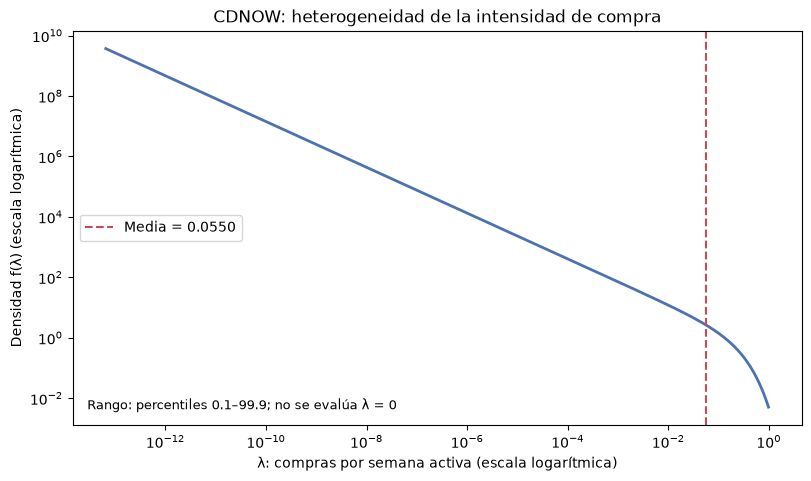

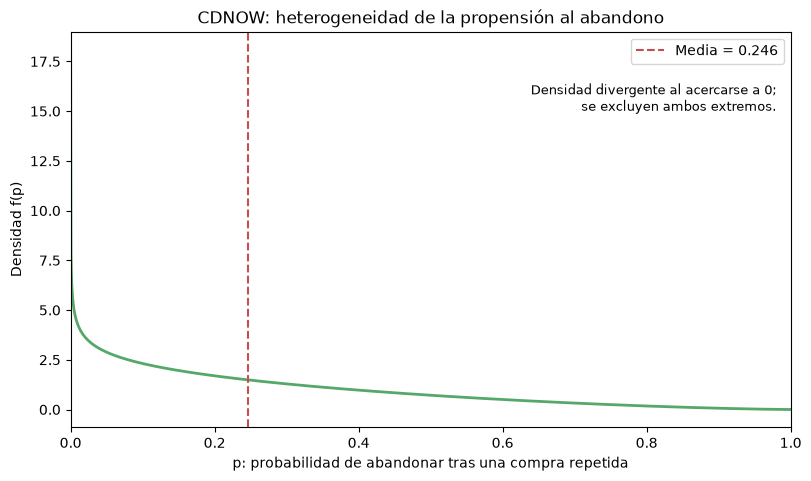

In [7]:
lambda_grid = np.geomspace(dist_lambda.ppf(.001), dist_lambda.ppf(.999), 1600)
fig, ax = plt.subplots(figsize=(8, 4.7), layout='constrained')
ax.loglog(lambda_grid, dist_lambda.pdf(lambda_grid), color='#4C72B0', lw=2)
ax.axvline(r / alpha, color='#C44E52', ls='--', label=f'Media = {r/alpha:.4f}')
ax.set(title='CDNOW: heterogeneidad de la intensidad de compra',
       xlabel='λ: compras por semana activa (escala logarítmica)',
       ylabel='Densidad f(λ) (escala logarítmica)')
ax.text(.02, .04, 'Rango: percentiles 0.1–99.9; no se evalúa λ = 0', transform=ax.transAxes, fontsize=9)
ax.legend()
fig.savefig(FIGS / 'parte2_densidad_lambda.png', dpi=160)
plt.show()

p_grid = np.linspace(1e-5, 1 - 1e-5, 1800)
fig, ax = plt.subplots(figsize=(8, 4.7), layout='constrained')
ax.plot(p_grid, dist_p.pdf(p_grid), color='#55A868', lw=2)
ax.axvline(a / (a + b), color='#C44E52', ls='--', label=f'Media = {a/(a+b):.3f}')
ax.set(title='CDNOW: heterogeneidad de la propensión al abandono',
       xlabel='p: probabilidad de abandonar tras una compra repetida', ylabel='Densidad f(p)', xlim=(0, 1))
ax.text(.98, .8, 'Densidad divergente al acercarse a 0;\nse excluyen ambos extremos.',
        transform=ax.transAxes, ha='right', fontsize=9)
ax.legend()
fig.savefig(FIGS / 'parte2_densidad_p.png', dpi=160)
plt.show()

> **Pregunta 2.2.** ¿Cuál es la tasa de compra promedio de un cliente activo? ¿Cuál es la probabilidad promedio de morir después de una compra? ¿Qué dicen las densidades sobre qué tan parecidos son los clientes?

- **Tasa de compra promedio de un activo:** $E[\lambda] = r/\alpha \approx 0.055$ compras por semana, es decir, unas **2.9 compras al año** mientras el cliente sigue vivo.
- **Probabilidad promedio de morir después de una compra:** $E[p] = a/(a+b) \approx 0.25$. En promedio, uno de cada cuatro clientes se va después de cada compra repetida.
- **Los clientes son muy distintos entre sí.** Con $r \approx 0.24 < 1$, la densidad gamma de $\lambda$ es decreciente y tiene la moda en cero: la mayoría de los clientes compra muy poco (muchos casi nada) y unos pocos compran mucho más que el promedio, que está jalado por esa cola larga. La beta de $p$, con $a < 1$ y $b > 1$, tiene forma de J: concentra a la mayoría en probabilidades de muerte bajas (≈ 32 % tiene $p < 0.1$), pero con una cola de clientes muy propensos a irse (≈ 14 % tiene $p > 0.5$); su desviación estándar (≈ 0.21) es casi tan grande como la media. Un mismo "cliente promedio" no describe bien a nadie: hay que pensar en una mezcla de clientes leales y activos con otros que compran poco o se van rápido.

## 2.3 · Bootstrap no paramétrico sobre clientes (bono incluido)

Se sortean **200 muestras de 2,357 filas**, con reemplazo, mediante
`np.random.default_rng(14045)`. Cada aparición se pasa al ajustador: nunca se agrupan
los identificadores sorteados. El arranque es el logaritmo del ajuste completo.

Hay como máximo tres llamadas por réplica: ajuste completo; completo/unos/artículo;
completo y dos perturbaciones. Los reintentos usan `SeedSequence([271828, réplica])`
y conservan la misma muestra. Los fallos y las cotas permanecen en los archivos.
La DE usa `ddof=1` y solo resultados aceptados, indicando siempre su número. Cualquier
fallo sin resolver impide afirmar que las 200 réplicas son válidas.

In [8]:
def progreso(replica, total, fila):
    if replica % 25 == 0 or not fila['aceptada']:
        print(f"Réplica {replica}/{total}: aceptada={fila['aceptada']}, reintentos={fila['reintentos']}")

boot, boot_diagnosticos = bootstrap_clientes(
    x, tx, T, params, B=B, semilla=SEMILLA,
    semilla_reintentos=SEMILLA_REINTENTOS, progreso=progreso)
boot.to_csv(RESULTADOS / 'bootstrap_cdnow.csv', index=False, float_format='%.17g')
guardar_json('bootstrap_cdnow_diagnosticos.json', boot_diagnosticos)
aceptadas = int(boot.aceptada.sum())
no_resueltas = B - aceptadas
se = boot.loc[boot.aceptada, list(NOMBRES)].std(ddof=1)

# Verificar las 200 muestras sin volver a ajustar: secuencia y multiplicidad.
rng_auditoria = np.random.default_rng(SEMILLA)
for fila in boot.itertuples():
    idx = rng_auditoria.integers(0, len(x), size=len(x), dtype=np.int64)
    assert hashlib.sha256(idx.astype('<i8').tobytes()).hexdigest() == fila.indices_sha256
    _, mult = np.unique(idx, return_counts=True)
    assert fila.n_clientes == len(x) and mult.sum() == len(x)
    assert fila.n_clientes_distintos == len(mult) and fila.multiplicidad_maxima == mult.max()
assert len(boot) == B and boot.replica.is_unique
print(f'Intentadas: {B}; aceptadas: {aceptadas}; no resueltas: {no_resueltas}; '
      f'en cota: {int(boot.en_cota.sum())}; reintentos externos: {int(boot.reintentos.sum())}')
display(se.rename('Error estándar bootstrap (ddof=1)').to_frame())

Réplica 25/200: aceptada=True, reintentos=0


Réplica 50/200: aceptada=True, reintentos=0


Réplica 75/200: aceptada=True, reintentos=0


Réplica 100/200: aceptada=True, reintentos=0


Réplica 125/200: aceptada=True, reintentos=0


Réplica 150/200: aceptada=True, reintentos=0


Réplica 175/200: aceptada=True, reintentos=0


Réplica 200/200: aceptada=True, reintentos=0
Intentadas: 200; aceptadas: 200; no resueltas: 0; en cota: 0; reintentos externos: 0


,Error estándar bootstrap (ddof=1)
r,0.0147477912967447
alpha,0.4625973405039646
a,0.1938949984277958
b,0.8007346204874723


In [9]:
# Evidencia existente de Herman; no se vuelven a ejecutar los 80 ajustes.
ruta_sim = RAIZ / 'notebooks/01_modelo_y_simulacion.ipynb'
nb_sim = nbformat.read(ruta_sim, as_version=4)
celda_sim = next(c for c in nb_sim.cells if c.get('id') == 'f91acd6a')
texto_sim = '\n'.join(o.get('data', {}).get('text/plain', '') for o in celda_sim.get('outputs', []))
patrones = [r'principal r\s+0\.25\s+0\.251\s+0\.010',
            r'(?m)^\s+alpha\s+4\.00\s+3\.943\s+0\.326',
            r'(?m)^\s+a\s+0\.80\s+0\.817\s+0\.168',
            r'(?m)^\s+b\s+2\.50\s+2\.491\s+0\.671']
assert all(re.search(p, texto_sim) for p in patrones), 'Revisar fuente de DE simuladas'
sd_sim = pd.Series({'r': .010, 'alpha': .326, 'a': .168, 'b': .671})
tabla_se = pd.DataFrame({'SE bootstrap': se, 'DE simulación (redondeada)': sd_sim})
tabla_se['Razón bootstrap / simulación'] = se / sd_sim
display(tabla_se)

resumen_boot = {
    'B': B, 'semilla_muestreo': SEMILLA, 'generador': 'numpy.default_rng / PCG64',
    'semilla_reintentos': SEMILLA_REINTENTOS, 'max_llamadas_por_replica': 3,
    'n_por_muestra': len(x), 'intentadas': B, 'aceptadas': aceptadas,
    'no_resueltas': no_resueltas, 'en_cota': int(boot.en_cota.sum()),
    'reintentos_externos_total': int(boot.reintentos.sum()),
    'reintentos_discrepancia_total': int(boot.reintentos_discrepancia.sum()),
    'ddof': 1, 'errores_estandar': {k: float(se[k]) for k in NOMBRES},
    'arranque_parametros': params, 'arranque_log': log_completo.tolist(),
    'datos_sha256': sha256(ruta_datos),
    'historias_sha256': hashlib.sha256(np.column_stack([x, tx, T]).astype('<f8').tobytes()).hexdigest(),
    'versiones': versiones, 'replicas_csv_sha256': sha256(RESULTADOS / 'bootstrap_cdnow.csv'),
    'simulacion_comparacion': {
        'fuente': 'notebooks/01_modelo_y_simulacion.ipynb', 'celda_id': 'f91acd6a',
        'fuente_sha256': sha256(ruta_sim), 'precision': 'DE guardadas redondeadas a 3 decimales',
        'DE': sd_sim.to_dict(), 'parametros': {'r': .25, 'alpha': 4, 'a': .8, 'b': 2.5},
        'n': 2357, 'replicas': 40, 'T': 'Uniforme(27,39) semanas'},
    'estado': 'completo' if no_resueltas == 0 else 'incompleto: fallos sin resolver',
}
guardar_json('bootstrap_cdnow_resumen.json', resumen_boot)
assert aceptadas == B and no_resueltas == 0, 'Resultados guardados; resolver fallos antes de declarar completitud'
assert np.isfinite(boot[list(NOMBRES) + ['ll']]).all().all()
assert (boot[list(NOMBRES)] > 0).all().all()

,SE bootstrap,DE simulación (redondeada),Razón bootstrap / simulación
r,0.0147477912967447,0.010,1.4747791296744688
alpha,0.4625973405039646,0.326,1.4190102469446766
a,0.1938949984277958,0.168,1.1541368954035460
b,0.8007346204874723,0.671,1.1933451870156071


### Qué se compara y qué no

El bootstrap aproxima la variabilidad al remuestrear la distribución empírica de
clientes CDNOW, incluyendo sus edades observadas y su mezcla real de historias.
Herman genera muestras nuevas bajo un BG/NBD conocido, con parámetros cercanos
pero distintos y edades uniformes. Ambos estudios describen dispersión del mismo
estimador; no usan idéntico diseño ni la misma población. Además, 40 simulaciones y
200 remuestras tienen error Monte Carlo. Las DE de Herman están guardadas con tres
decimales; no se inventa precisión adicional. Una diferencia no demuestra por sí sola
un error del ajustador ni equivalencia entre las dos medidas.

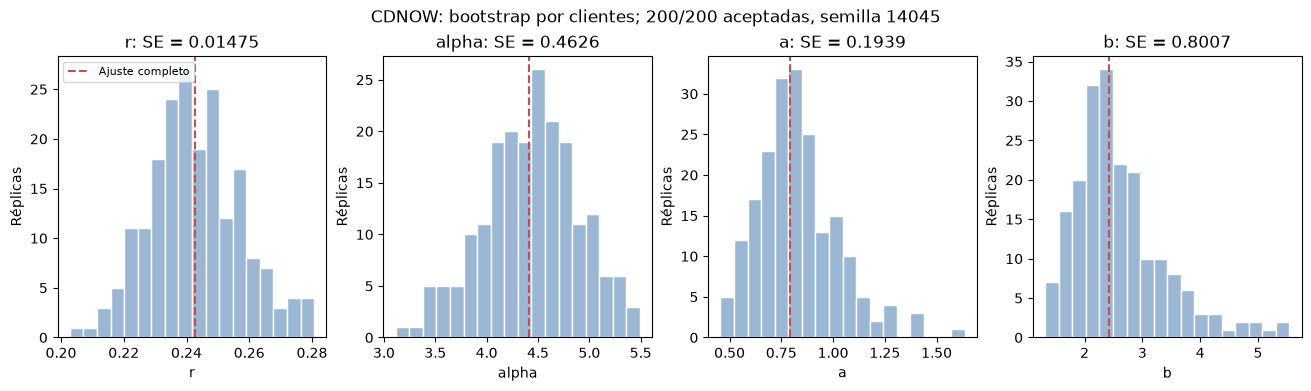

**Contabilidad:** 200 intentadas, 200 aceptadas, 0 sin resolver. Las DE relativas al ajuste completo son r: 6.1%, alpha: 10.5%, a: 24.5%, b: 33.0%. La tabla anterior permite comparar las magnitudes y sus razones sin confundir diseños.

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8), layout='constrained')
for ax, k in zip(axes, NOMBRES):
    ax.hist(boot.loc[boot.aceptada, k], bins=18, color='#9bb7d4', edgecolor='white')
    ax.axvline(params[k], color='#C44E52', ls='--', label='Ajuste completo')
    ax.set(title=f'{k}: SE = {se[k]:.4g}', xlabel=k, ylabel='Réplicas')
axes[0].legend(fontsize=8)
fig.suptitle(f'CDNOW: bootstrap por clientes; {aceptadas}/{B} aceptadas, semilla {SEMILLA}')
fig.savefig(FIGS / 'parte2_bootstrap_parametros.png', dpi=160)
plt.show()
display(Markdown(
    f'**Contabilidad:** {B} intentadas, {aceptadas} aceptadas, {no_resueltas} sin resolver. '
    f'Las DE relativas al ajuste completo son '
    + ', '.join(f'{k}: {se[k]/params[k]:.1%}' for k in NOMBRES) + '. '
    'La tabla anterior permite comparar las magnitudes y sus razones sin confundir diseños.'
))

> **Pregunta 2.3 (bono).** Estimen el error estándar de cada parámetro con bootstrap sobre clientes y compárenlo con la dispersión de la simulación 1.3.

Las 200 réplicas convergieron sin tocar las cotas. Los errores estándar son ≈ 0.015 para $r$, ≈ 0.46 para $\alpha$, ≈ 0.19 para $a$ y ≈ 0.80 para $b$; relativos al estimado, ≈ 6 %, ≈ 10 %, ≈ 24 % y ≈ 33 %. **Es el mismo patrón que en la simulación de 1.3:** $r$ y $\alpha$ se estiman con mucha más precisión que $a$ y $b$, porque las compras se observan directamente y la muerte no (y los clientes con $x = 0$ no informan sobre $p$).

Los errores estándar del bootstrap son entre ≈ 15 % ($a$, $b$) y ≈ 47 % ($r$) más grandes que las DE de la simulación (0.010, 0.326, 0.168 y 0.671). Es razonable: la simulación genera datos que cumplen el BG/NBD al pie de la letra, con $T$ uniforme y parámetros parecidos pero no iguales a los de CDNOW, mientras que el bootstrap remuestrea a los clientes reales, que no siguen el modelo exactamente. El orden de magnitud coincide, así que la incertidumbre que vimos en 1.3 es una buena guía de la que tenemos en CDNOW.